# Neural topology optimization
## Introduction
This notebook demonstrates how `metatopia` can be used to set up neural topology optimization for a single task. We'll walk through the key components of the optimization process, from setting up the problem to visualizing the results. First, let's import all necessary libraries:

In [16]:
import equinox as eqx
import jax
import jax.random as jr
import matplotlib.pyplot as plt
import metatopia as mtp
import optax
from equinox.internal import scan


# Enable 64-bit precision
jax.config.update("jax_enable_x64", True)

## Problem setup
Let's start by setting up the solver used in the iterative procedure, and the boundary conditions for the Messerschmitt–Bölkow–Blohm (MBB) beam problem - a classic benchmark in topology optimization. 

In [17]:
# Define domain shape for MBB beam
Nx = 128  # Number of elements in the x-direction
Ny = 64  # Number of elements in the y-direction

# Define domain size
Lx = 2.0  # Domain size in the x-direction
Ly = 1.0  # Domain size in the y-direction

domain_shape = (Nx, Ny)

# Setup the solver
solver = mtp.solver.setup_solver_cvxopt(
    Nx=Nx,
    Ny=Ny,
    Lx=Lx,
    Ly=Ly,
    young=1.0,
    young_min=1e-9,
    poisson=0.3,
    penalty=3.0,
)

# Set up the MBB problem
problem = mtp.dataset.to.mbb_beam(width=Nx, height=Ny, target_vf=0.3)

## Create a neural reparameterization model
Now, let's create a neural network which will map the spatial coordinates of element centroids $\mathbf{x}\in \Omega$ to density values $\rho(\mathbf{x})$. We start by creating a grid of coordinates. 

In [18]:
coords = mtp.utils.get_grid_coords(domain_shape)

Next, we create a SIREN neural network to perform the mapping from 2D coordinates (`in_features=2`) to densities (`out_features=1`). For convenience, we split the model into learnable (`params`), and frozen (`static`) parameters.

In [19]:
model = mtp.models.Siren(
    in_features=2,
    out_features=1,
    hidden_features=256,
    hidden_layers=4,
    outermost_linear=True,
    omega_0=60.0,
    key=jr.PRNGKey(42),
)

params, static = eqx.partition(model, eqx.is_array)

Now, we define the mapping from model parameters $\theta$ to a full designs. The design parameterization consists of a SIREN network, which is applied to all centroid coordinates, and two filtering operations - one to enforce lengthscale, and one to enforce the volume fraction. 

In [20]:
def design_parameterization(params, static):
    model = eqx.combine(params, static)
    rho = jax.vmap(model)(coords)
    rho = 10.0 * rho  # Boost the signal before passing through filters
    rho = mtp.filters.cone_filter(design=rho, domain_shape=domain_shape, r_min=2.0)

    rho = mtp.filters.hoyer_volume_enforcing_filter(
        design=rho, target_vf=problem["target_vf"]
    )
    return rho.reshape(domain_shape)

We can validate this function by applying it to the initialized model parameters.  

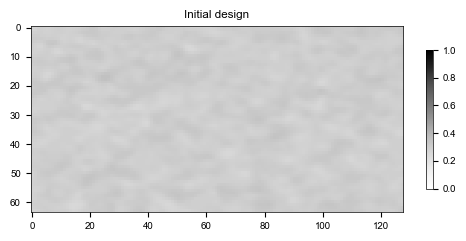

In [ ]:
initial_rho = design_parameterization(params, static)


def plot_design(rho, title):
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    im = ax.imshow(
        rho.reshape(domain_shape),
        vmin=0.0,
        vmax=1.0,
        cmap="Grays",
        interpolation="none",
    )
    ax.set_title(title)
    plt.colorbar(im, ax=ax, shrink=0.3)


plot_design(initial_rho, "Initial design")

Not very interesting, eh? Let's change that by performing optimization!

## Set up the optimization process
First, let's create a loss function which returns the compliance of a structure corresponding to the input set of parameters $\theta$ Note, that we also output the corresponding designs $\rho$. Later, this will be used to track how the structure changes across iterations.


In [22]:
def loss_fn(params):
    rho = design_parameterization(params, static)
    compliance = solver(rho, problem)
    loss = compliance
    return loss, {"rho": rho}

Now, let's define and initialize the Adam optimizer from Optax.

In [23]:
opt = optax.adam(1e-4)
# Initialize with learnable parameters (only!)
opt_state = opt.init(params)

Finally, let's create functions for updating the neural network parameters based on gradients of the loss function. 

In [24]:
def make_step(params, opt_state):
    (loss, metrics), grads = eqx.filter_value_and_grad(loss_fn, has_aux=True)(params)

    updates, opt_state = opt.update(grads, opt_state, params)
    params = eqx.apply_updates(params, updates)

    return params, opt_state, loss, metrics

## Optimize the design
Rather than using a standard Python loop for optimization, we use JAX's scan function, which offers several advantages:

1. **Efficiency**: scan compiles the iteration into efficient XLA (Accelerated Linear Algebra) operations, making it significantly faster than Python loops.

2. **Automatic trajectory collection**: scan automatically accumulates auxiliary outputs (like losses and designs) during iteration, eliminating the need for manual list management.

3. **JIT compatibility**: Unlike Python loops, scan can be JIT-compiled, enabling further performance optimizations


We optimize for 100 steps. The code block below might take some time to run.

In [25]:
def scan_fn(carry, _):
    params, opt_state = carry
    params, opt_state, loss, metrics = make_step(params, opt_state)
    return (params, opt_state), (loss, metrics)


n_steps = 100

(params, opt_state), (losses, metrics) = scan(
    scan_fn,
    (params, opt_state),
    None,
    length=n_steps + 1,  # For the final loss
    kind="lax",
)

Let's see what the optimized structure looks like.

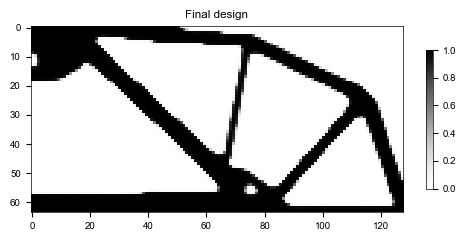

In [26]:
rhos = metrics["rho"]  # Extract the design from the metrics
plot_design(rhos[-1], "Final design")

We can also plot the optimization trajectory to see how the design evolved throughout the iterations. The animation is saved to a separate file in the notebook directory.

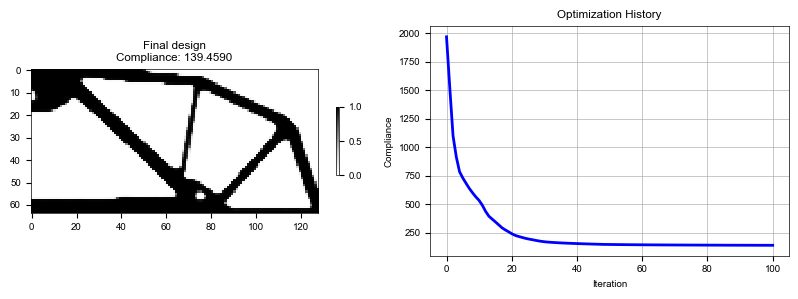

In [28]:
def plot_optimization_trajectory(rhos, losses, domain_shape):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))

    # Plot final design
    im = ax1.imshow(
        rhos[-1].reshape(domain_shape),
        vmin=0.0,
        vmax=1.0,
        cmap="Grays",
        interpolation="none",
    )
    ax1.set_title(f"Final design\nCompliance: {losses[-1]:.4f}")
    plt.colorbar(im, ax=ax1, shrink=0.3)

    # Plot loss history
    ax2.plot(losses, "b-", linewidth=2.0)
    ax2.set_title("Optimization History")
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("Compliance")
    ax2.grid(True)

    plt.tight_layout()


plot_optimization_trajectory(rhos, losses, domain_shape)

## Next steps
This notebook introduced the fundamentals of neural topology optimization. When meta-learning, the demonstrated optimization procedure is vmapped across a batch of tasks to form the inner optimization loop. For further experimentation with different neural architectures, optimizers and problem settings, we recommend using the `experiment/neural_topology_optimization` script which uses Hydra configurations to make parameter exploration and experimentation straightforward and systematic.
